In [94]:
# E-Commerce Customer Churn Classification (AIE322)
## Part 1: Data Cleaning, EDA & Reproducible Splitting

In [95]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("E Commerce Dataset.xlsx", sheet_name="E Comm")
df.drop(columns=['CustomerID'], inplace=True)
df.drop_duplicates(inplace=True)

print("Shape:", df.shape)
print(df.isnull().sum()[df.isnull().sum() > 0])
df.head()

Shape: (5074, 19)
Tenure                         231
WarehouseToHome                221
HourSpendOnApp                 230
OrderAmountHikeFromlastYear    252
CouponUsed                     210
OrderCount                     243
DaySinceLastOrder              288
dtype: int64


,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60


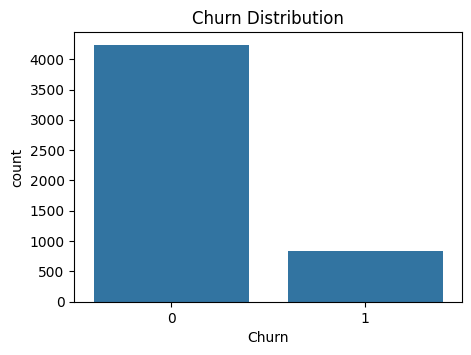

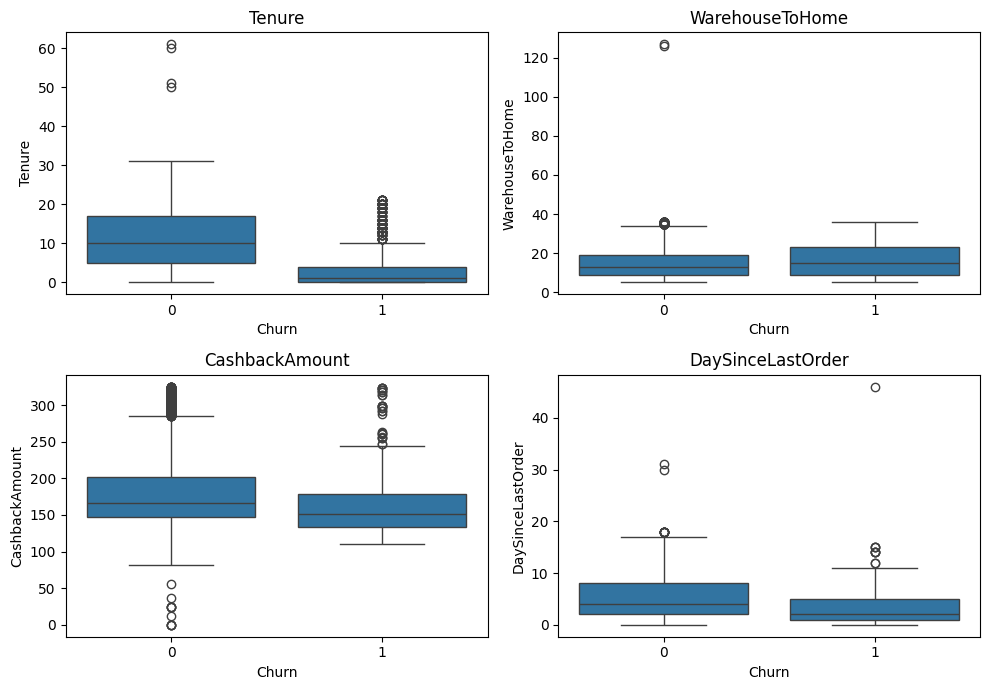

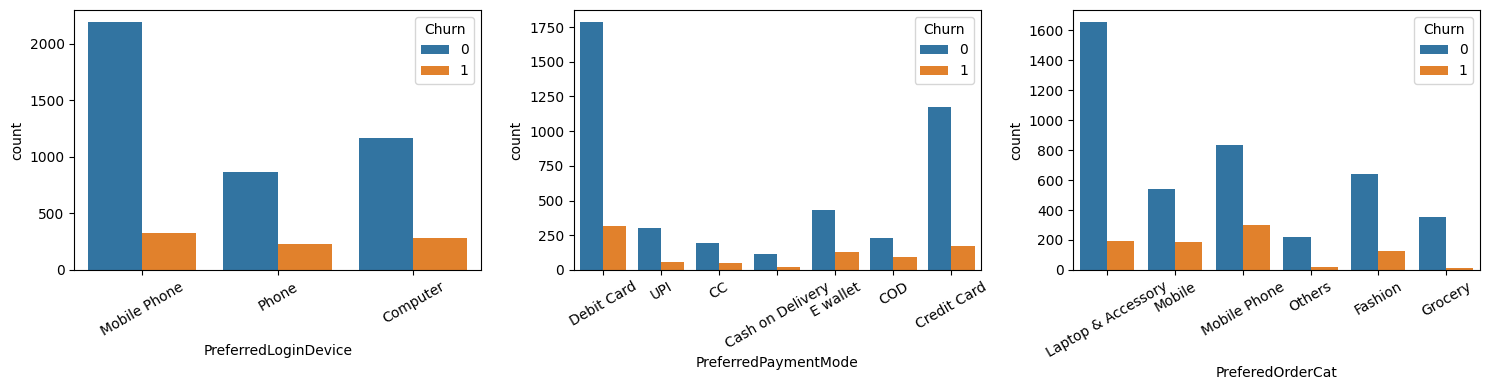

In [96]:
plt.figure(figsize=(5, 3.5))
sns.countplot(x='Churn', data=df)
plt.title('Churn Distribution')
plt.show()

num_eda = ['Tenure', 'WarehouseToHome', 'CashbackAmount', 'DaySinceLastOrder']
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for i, col in enumerate(num_eda):
    sns.boxplot(x='Churn', y=col, data=df, ax=axes[i//2, i%2])
    axes[i//2, i%2].set_title(col)
plt.tight_layout()
plt.show()

cat_eda = ['PreferredLoginDevice', 'PreferredPaymentMode', 'PreferedOrderCat']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(cat_eda):
    sns.countplot(x=col, hue='Churn', data=df, ax=axes[i])
    axes[i].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

In [97]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Churn'])
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

In [98]:
# Why is setting `random_state` essential when splitting datasets in scikit-learn?
#
# Setting `random_state` fixes the random seed so the data is split into the exact same training and testing sets every time the code runs. This ensures reproducible results and allows fair comparison between different models.

# ## Part 2: Preprocessing Pipelines (`ColumnTransformer` & `Pipeline`)

In [99]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', MinMaxScaler())
])

imp = SimpleImputer(strategy='median')
imp.fit(X_train[num_cols])
print("Medians (statistics_):", imp.statistics_)

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

cat_imp = SimpleImputer(strategy='most_frequent').fit_transform(X_train[cat_cols])
ohe = OneHotEncoder(handle_unknown='ignore')
encoded = ohe.fit_transform(cat_imp)
print("OHE Output Type:", type(encoded))

Medians (statistics_): [  9.     1.    13.     3.     4.     3.     3.     0.    15.     1.
   2.     3.   163.49]
OHE Output Type: <class 'scipy.sparse._csr.csr_matrix'>


In [100]:
# **1. Why `.statistics_` is used instead of `.median_` in `SimpleImputer`:**
# `SimpleImputer` supports multiple strategies (`mean`, `median`, `most_frequent`, `constant`). Scikit-learn uses a single standardized attribute `.statistics_` to store the learned values regardless of the chosen strategy.

# **2. Why scikit-learn returns a Sparse Matrix by default from `OneHotEncoder`:**
# One-hot encoding creates many columns filled mostly with zeros. Storing only the non-zero positions in a sparse matrix saves a large amount of memory and speeds up computation compared to a dense NumPy array.

In [101]:
from sklearn.linear_model import LogisticRegression

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

pipeline.fit(X_train, y_train)
print("Test Accuracy:", pipeline.score(X_test, y_test))

Test Accuracy: 0.8817733990147784


In [102]:
# **What happens internally when `pipeline.fit(X_train, y_train)` is executed?**
#
# 1. **Transformers (`preprocessor`):** Scikit-learn calls `.fit_transform(X_train, y_train)` sequentially on each transformer step, learning parameters from the training data only and passing the transformed features forward.
# 2. **Final Estimator (`classifier`):** Scikit-learn calls `.fit(X_transformed, y_train)` on the final estimator using the preprocessed training features to train the model.

# ## Part 3: Model Complexity, Bias-Variance & Regularization

In [103]:
from sklearn.tree import DecisionTreeClassifier

pipe_underfit = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DecisionTreeClassifier(max_depth=1, random_state=42))
])
pipe_underfit.fit(X_train, y_train)

pipe_complex = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DecisionTreeClassifier(max_depth=None, random_state=42))
])
pipe_complex.fit(X_train, y_train)

print("Underfit (max_depth=1) - Train:", pipe_underfit.score(X_train, y_train), "Test:", pipe_underfit.score(X_test, y_test))
print("Complex (max_depth=None) - Train:", pipe_complex.score(X_train, y_train), "Test:", pipe_complex.score(X_test, y_test))

Underfit (max_depth=1) - Train: 0.8435575264843558 Test: 0.8246305418719212
Complex (max_depth=None) - Train: 1.0 Test: 0.9586206896551724


In [104]:
# **1. What happens to bias and variance as model complexity increases?**
# As model complexity increases, **bias decreases** (the model fits training patterns better) and **variance increases** (the model becomes more sensitive to noise in the training data, risking overfitting).

# **2. Why increasing model complexity resolves underfitting, whereas adding more training examples does not:**
# Underfitting means the model is too simple (high bias) to capture the underlying patterns in the data. Adding more training data will not help an overly rigid model learn complex patterns, whereas increasing model complexity gives the model the capacity to fit the data properly.

In [105]:
configs = [
    ("L2 (Ridge)", LogisticRegression(penalty="l2", solver="saga", max_iter=2000, random_state=42)),
    ("L1 (Lasso)", LogisticRegression(penalty="l1", solver="saga", max_iter=2000, random_state=42)),
    ("Elastic Net", LogisticRegression(penalty="elasticnet", l1_ratio=0.5, solver="saga", max_iter=2000, random_state=42))
]

for name, clf in configs:
    pipe = Pipeline([('preprocessor', preprocessor), ('model', clf)])
    pipe.fit(X_train, y_train)
    zeros = np.sum(np.isclose(pipe.named_steps['model'].coef_, 0, atol=1e-4))
    print(f"{name} -> Train: {pipe.score(X_train, y_train):.4f} | Test: {pipe.score(X_test, y_test):.4f} | Zero weights: {zeros}")

L2 (Ridge) -> Train: 0.8923 | Test: 0.8818 | Zero weights: 0
L1 (Lasso) -> Train: 0.8950 | Test: 0.8837 | Zero weights: 5
Elastic Net -> Train: 0.8946 | Test: 0.8818 | Zero weights: 4


In [106]:
## Part 4: Ensemble Learning (Bagging, Pasting, AdaBoost & Voting)

In [107]:
from sklearn.ensemble import BaggingClassifier

bag_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', BaggingClassifier(DecisionTreeClassifier(random_state=42), n_estimators=100, bootstrap=True, oob_score=True, n_jobs=-1, random_state=42))
])
bag_model.fit(X_train, y_train)

paste_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', BaggingClassifier(DecisionTreeClassifier(random_state=42), n_estimators=100, bootstrap=False, n_jobs=-1, random_state=42))
])
paste_model.fit(X_train, y_train)

print("OOB Score:", bag_model.named_steps['model'].oob_score_)
print("Bagging Test Accuracy:", bag_model.score(X_test, y_test))
print("Pasting Test Accuracy:", paste_model.score(X_test, y_test))

OOB Score: 0.9576250307957626
Bagging Test Accuracy: 0.9665024630541872
Pasting Test Accuracy: 0.9527093596059113


In [108]:
# **1. What does setting `n_jobs=-1` instruct scikit-learn to do?**
# It instructs scikit-learn to use all available CPU cores in parallel to speed up training and prediction.

from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

ada_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', AdaBoostClassifier(n_estimators=100, random_state=42))
])
ada_model.fit(X_train, y_train)
y_pred = ada_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-Score:", f1_score(y_test, y_pred))

# **2. Which ensemble technique is used when `bootstrap=False`?**
# **Pasting** (sampling without replacement).

# **3. Main advantage of Out-of-Bag (OOB) evaluation:**
# The `oob_score_` is close to the test accuracy and evaluates the model on the ~37% of training instances not sampled for each tree. Its main advantage is providing a reliable validation score without needing a separate validation set.

Accuracy: 0.8827586206896552
Precision: 0.6788321167883211
Recall: 0.5535714285714286
F1-Score: 0.6098360655737705


In [109]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

ada_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', AdaBoostClassifier(n_estimators=100, random_state=42))
])
ada_model.fit(X_train, y_train)
y_pred = ada_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-Score:", f1_score(y_test, y_pred))

Accuracy: 0.8827586206896552
Precision: 0.6788321167883211
Recall: 0.5535714285714286
F1-Score: 0.6098360655737705


In [110]:
# **In AdaBoost, what happens to the weights of misclassified instances from one iteration to the next, and why?**
#
# The weights of misclassified instances are **increased** in the next iteration so that the next weak learner focuses more on correcting those hard-to-classify examples.

In [111]:
from sklearn.ensemble import VotingClassifier, RandomForestClassifier
from sklearn.svm import SVC

estimators = [
    ('lr', LogisticRegression(max_iter=1000, random_state=42)),
    ('rf', RandomForestClassifier(n_estimators=100, random_state=42)),
    ('svc', SVC(probability=True, random_state=42))
]

hard_voting = Pipeline([
    ('preprocessor', preprocessor),
    ('model', VotingClassifier(estimators=estimators, voting='hard'))
])
hard_voting.fit(X_train, y_train)

soft_voting = Pipeline([
    ('preprocessor', preprocessor),
    ('model', VotingClassifier(estimators=estimators, voting='soft'))
])
soft_voting.fit(X_train, y_train)

print("Hard Voting Test Accuracy:", hard_voting.score(X_test, y_test))
print("Soft Voting Test Accuracy:", soft_voting.score(X_test, y_test))

Hard Voting Test Accuracy: 0.9014778325123153
Soft Voting Test Accuracy: 0.9064039408866995


In [112]:
import os, pandas as pd

print("Current dir:", os.getcwd())
print("Files in current dir:", os.listdir("."))

# لو الملف مش في المسار الحالي، نبحث عنه في كل فولدرات Colab:
file_path = None
for root, dirs, files in os.walk("/content"):
    if "E Commerce Dataset.xlsx" in files:
        file_path = os.path.join(root, "E Commerce Dataset.xlsx")
        break

print("Found at:", file_path)
df = pd.read_excel(file_path, sheet_name="E Comm")
df.drop(columns=['CustomerID'], inplace=True)
df.drop_duplicates(inplace=True)
print("Shape:", df.shape)

Current dir: /content
Files in current dir: ['.config', 'E Commerce Dataset.xlsx', 'sample_data']
Found at: /content/E Commerce Dataset.xlsx
Shape: (5074, 19)
